# Sample-area conventions: centre-in, all-in and reconstruction

**A concentration is a count divided by a sampled volume, and the sampled area depends on which
particles a processing chain agrees to count.** Three conventions are in common use for optical
array probes, and NCAR's Process2D (GitHub `NCAR/aircraft_oap`, Apache-2.0; related work) offers
all three as options, as do this package's engines:

| Convention | Effective array width (EAW) | Particles it counts | Source |
|---|---|---|---|
| **Centre-in** | `N × Res` | images whose centre falls on the array | DMT CIP manual Eq. 2.3; Heymsfield & Parrish (1978) Eq. 7 |
| **All-in** | `Res × (N − X − 1)`, X = diodes shadowed | images that shadow neither end element | DMT Eq. 2.2; Heymsfield & Parrish (1978) Eq. 6 |
| **Reconstruction** | `N × Res + 0.72 D` | partial images too, with their size reconstructed | Heymsfield & Parrish (1978) Eq. 17 (`1 − 2/7.25 = 0.7241`, rounded) |

In every convention the sample area is EAW × depth of field, with the depth of field
`DOF = ±3R²/λ` (DMT Eq. 2.4, so `6R²/λ` in total) **clamped at the arm separation**: a particle
cannot be in focus outside the space between the probe's arms (DMT: *"the value must be truncated
at 100 mm"*).

This notebook computes the three sample areas per size for a 64-diode, 25 µm probe, divides one
fixed-seed synthetic set of counts by each, and reports the differences in dB per bin. It runs in
well under a second and reads no data.

**Before this:** [01_start_here](../1_getting_started/01_start_here.ipynb) (Start here: process one probe file and look at what came out). **Related:** [02_counting_uncertainty](../6_science/02_counting_uncertainty.ipynb). **Needs:** `pip install "arrayprobe[extra]"` (matplotlib).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/4_methods_and_literature/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

## 1. The probe and the size bins

The probe is CIP-like: 64 diodes at 25 µm, a 658 nm laser and 100 mm arms (the vendor maximum;
installations with 40-70 mm arms exist, and in the arm-limited bins concentration scales as
`1/arm`, so take the real value from the probe). Bins are 50 µm wide; X, the number of diodes a
particle shadows, is taken as `D / Res` at the bin centre.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

N_DIODES = 64
RES_MM = 0.025          # pixel size
WAVELENGTH_MM = 658e-6  # laser wavelength
ARM_MM = 100.0          # arm separation: the depth of field can never exceed it

edges_mm = np.arange(0.025, 1.6001, 0.050)
d_mm = 0.5 * (edges_mm[:-1] + edges_mm[1:])
dd_mm = np.diff(edges_mm)
x_diodes = d_mm / RES_MM
print(f"{d_mm.size} bins, centres {d_mm[0]*1e3:.0f}-{d_mm[-1]*1e3:.0f} µm")

31 bins, centres 50-1550 µm


## 2. Depth of field, clamped at the arms

The unclamped depth of field grows as D², so above a crossover size every particle is in focus
across the whole gap between the arms and the sample area stops depending on the optics.

In [3]:
def depth_of_field_mm(d_mm, wavelength_mm=WAVELENGTH_MM, arm_mm=ARM_MM):
    radius = d_mm / 2.0
    return np.minimum(6.0 * radius**2 / wavelength_mm, arm_mm)   # +/-3R^2/lambda, clamped

dof = depth_of_field_mm(d_mm)
d_cross_um = 2e3 * np.sqrt(ARM_MM * WAVELENGTH_MM / 6.0)
print(f"DOF reaches the {ARM_MM:.0f} mm arms at D = {d_cross_um:.0f} um; "
      f"{int(np.sum(dof < ARM_MM))} of {d_mm.size} bins are optics-limited, the rest arm-limited")

DOF reaches the 100 mm arms at D = 209 um; 4 of 31 bins are optics-limited, the rest arm-limited


## 3. The three effective array widths and sample areas

All-in is undefined once a particle shadows `N − 1` diodes or more (the width reaches zero): such
an image always covers an end element and is rejected, so those bins hold no all-in
concentration at all. Heymsfield & Parrish (1978, Table 1) found 80 % of particles ≥ 600 µm
touched an end element on a 1024 µm array, which is the practical case against all-in for large
particles.

In [4]:
def eaw_centre_in(d_mm):
    return np.full_like(d_mm, N_DIODES * RES_MM)

def eaw_all_in(d_mm):
    x = d_mm / RES_MM
    width = RES_MM * (N_DIODES - x - 1)
    return np.where(width > 0, width, np.nan)          # no all-in sample area: always rejected

def eaw_reconstruction(d_mm):
    return N_DIODES * RES_MM + 0.72 * d_mm

conventions = {"centre-in": eaw_centre_in, "all-in": eaw_all_in,
               "reconstruction": eaw_reconstruction}
sample_area_mm2 = {name: f(d_mm) * dof for name, f in conventions.items()}

print(f"{'D (um)':>7} " + " ".join(f"{n:>15}" for n in conventions) + "   (sample area, mm^2)")
for i in range(0, d_mm.size, 4):
    print(f"{d_mm[i]*1e3:7.0f} " + " ".join(f"{sample_area_mm2[n][i]:15.2f}" for n in conventions))

 D (um)       centre-in          all-in  reconstruction   (sample area, mm^2)
     50            9.12            8.69            9.32
    250          160.00          132.50          178.00
    450          160.00          112.50          192.40
    650          160.00           92.50          206.80
    850          160.00           72.50          221.20
   1050          160.00           52.50          235.60
   1250          160.00           32.50          250.00
   1450          160.00           12.50          264.40


## 4. One set of counts, three concentrations

The counts below are a fixed-seed Poisson draw from a gamma size distribution, built so that the
centre-in convention recovers it. The same counts are divided by each sample area here to
isolate the area term; in a real run each convention also changes *which* particles are counted
(all-in drops end-element images, reconstruction adds partial ones), so the counts differ too.
The differences are reported in dB, `10 log10(N_conv / N_centre-in)`.

In [5]:
rng = np.random.default_rng(31)
TAS_M_S, SECONDS = 100.0, 60.0
swept_m = TAS_M_S * SECONDS

n0, mu, slope = 2.0e5, 1.0, 8.0          # per litre per mm, gamma shape, per mm
truth_per_l_mm = n0 * d_mm**mu * np.exp(-slope * d_mm)
volume_l = sample_area_mm2["centre-in"] * 1e-6 * swept_m * 1e3   # mm^2 -> m^2, m^3 -> L
counts = rng.poisson(truth_per_l_mm * dd_mm * volume_l)

conc = {}
for name, sa in sample_area_mm2.items():
    vol_l = sa * 1e-6 * swept_m * 1e3
    conc[name] = np.where(counts > 0, counts / (vol_l * dd_mm), np.nan)

with np.errstate(invalid="ignore"):
    db = {name: 10 * np.log10(conc[name] / conc["centre-in"]) for name in conc}
print(f"{'D (um)':>7} {'counts':>7} {'all-in dB':>10} {'recon dB':>10}")
for i in range(0, d_mm.size, 4):
    print(f"{d_mm[i]*1e3:7.0f} {counts[i]:7d} {db['all-in'][i]:10.2f} {db['reconstruction'][i]:10.2f}")
total = {n: np.nansum(conc[n] * dd_mm) for n in conc}
for n in ("all-in", "reconstruction"):
    print(f"total concentration, {n} vs centre-in: {10*np.log10(total[n]/total['centre-in']):+.2f} dB"
          + (" (summed over the bins where all-in is defined)" if n == "all-in" else ""))

 D (um)  counts  all-in dB   recon dB
     50   18546       0.21      -0.10
    250  324951       0.82      -0.46
    450  118550       1.53      -0.80
    650   34646       2.38      -1.11
    850    9115       3.44      -1.41
   1050    2225       4.84      -1.68
   1250     553       6.92      -1.94
   1450     134      11.07      -2.18
total concentration, all-in vs centre-in: +0.94 dB (summed over the bins where all-in is defined)
total concentration, reconstruction vs centre-in: -0.45 dB


This cell plots the result. On the left, the sample area of each convention against particle size; on the right, the difference in decibels between the concentrations that the same counts give under each convention.

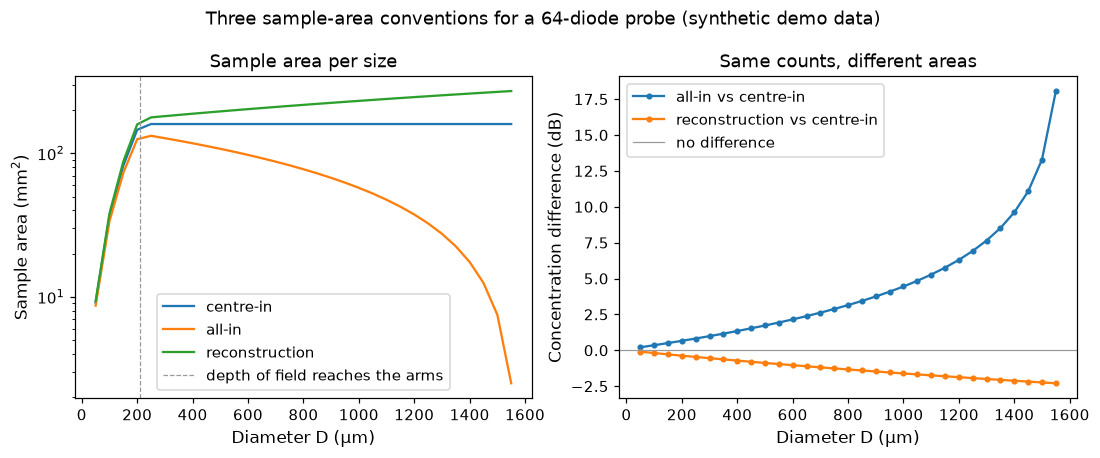

In [6]:
plt.rcParams.update({"font.size": 10, "legend.fontsize": 10})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
for name, sa in sample_area_mm2.items():
    ax1.plot(d_mm * 1e3, sa, label=name)
ax1.axvline(d_cross_um, color="0.6", lw=0.8, ls="--", label="depth of field reaches the arms")
ax1.set(xlabel="Diameter D (µm)", ylabel="Sample area (mm$^2$)", yscale="log",
        title="Sample area per size")
ax1.legend()
for name in ("all-in", "reconstruction"):
    ax2.plot(d_mm * 1e3, db[name], marker="o", ms=3, label=f"{name} vs centre-in")
ax2.axhline(0, color="0.6", lw=0.8, label="no difference")
ax2.set(xlabel="Diameter D (µm)", ylabel="Concentration difference (dB)",
        title="Same counts, different areas")
ax2.legend()
fig.suptitle("Three sample-area conventions for a 64-diode probe (synthetic demo data)")
fig.tight_layout()
plt.show()

*Figure 1. Left: the sample area each convention assigns to each size; the dashed grey line marks the crossover diameter above which the depth of field is clamped at the arm separation. Right: the concentration the same counts give under the all-in and reconstruction areas, relative to centre-in, in dB; the solid grey line is zero difference.*

## 5. When each convention is appropriate

- **Centre-in** is the default nearly everywhere (Heymsfield & Parrish call it *"the one most
  commonly employed in 2-D data reduction schemes"*). It needs no size reconstruction and its
  width does not depend on size, so its correction is the smallest and its sources agree
  exactly. Choose it unless there is a reason not to.
- **All-in** sizes every counted particle from a complete image, which is what a shape or habit
  analysis needs. Its cost grows with size: the width shrinks to nothing at `N − 1` diodes, so it
  is unusable for particles approaching the array width, and the large-size bins it does keep
  rest on few counts and a large correction (several dB above ~1 mm here).
- **Reconstruction** extends the measurable range past the array width by estimating the size of
  truncated images. It is the choice for large particles and broad ice distributions, at the
  price of a size assignment that rests on the reconstruction geometry rather than a full image.

Two cautions carry across all three. The depth-of-field clamp makes every bin above the crossover
size proportional to the arm separation, so a wrong arm value is a uniform offset in those bins.
And implementations differ in detail: UIOOPS's sample-area routine writes the all-in width as
`Res × (N − X + 1)`, two elements wider than the manual and the origin paper, so compare
conventions' formulas, not only their names, before comparing two products.